# Hierarchical splitting methods for coupled nonlinear mass-spring-damper chains

Author: Kevin Schäfers, kschaefers@uni-wuppertal.de
Date: 12.10.2026

---------------------------------------------------

This Jupyter notebook implements the hierarchical splitting methods used in 

*K. Schäfers, M. Günther: A hierarchical splitting approach for N-split differential equations*

to perform the numerical simulations for the coupled mass-spring-damper chains. The figures are exported as TikZ files via `matplot2tikz`.

In [1]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Markdown, display
import matplot2tikz

The class `CoupledPHS` provides a coupled port-Hamiltonian system

$$x' = \left( \mathcal{J} - \mathcal{R} \right) \nabla \mathcal{H}(x), \qquad x = (x_1,x_2), \qquad \mathcal{J} = \begin{pmatrix} \mathcal{J}_1 & C \\ -C^\top & \mathcal{J}_2 \end{pmatrix}, \qquad \mathcal{R} = \mathrm{diag}(r),$$

with a separable quartic Hamiltonian $\mathcal{H}(x) = \sum_j \left( \tfrac{a_j}{2} x_j^2 + \tfrac{b_j}{4} x_j^4 \right)$.

The class also stores the decomposition $\mathcal{J} - \mathcal{R} = \mathcal{J}^{\{2\}} + \mathcal{J}^{\{1\}} - \mathcal{R}$ into the three subsystems that the splitting methods below act on: the coupling $C$ is assigned to the fast chain 1, so that $\mathcal{J}^{\{2\}}$ acts on $x_1$ and on those components of $x_2$ that are coupled by $C$, whereas $\mathcal{J}^{\{1\}} = \mathcal{J}_2$ acts on $x_2$. Since $\mathcal{R}$ is nonzero only on components with $b_j = 0$, the flow of the dissipative subsystem is available in closed form.

In [2]:
class CoupledPHS:
    """
    Coupled port-Hamiltonian system  x' = (J - R) grad H(x),  x = (x1, x2),  with

        J = [[J1, C], [-C^T, J2]],   R = diag(r),   H(x) = sum_j ( a_j/2 x_j^2 + b_j/4 x_j^4 ).

    Splitting  J - R = J_fast + J_slow - R:  the coupling C is assigned to the fast chain 1, i.e.
    J_fast = [[J1, C_k], [-C_k^T, 0]] acts on x1 and the components k of x2 coupled by C, and J_slow = J2 acts on x2.
    R is nonzero only on components with b_j = 0, so the damping flow is solved exactly.
    """

    def __init__(self, J1, J2, C, r, a, b):
        n1, n2 = J1.shape[0], J2.shape[0]
        self.n = n1 + n2
        self.J = np.block([[J1, C], [-C.T, J2]])
        self.r, self.a, self.b = r, a, b

        k = np.flatnonzero(np.any(C != 0, axis=0))
        idx_fast = np.concatenate((np.arange(n1), n1 + k))
        idx_slow = np.arange(n1, self.n)
        J_fast = np.block([[J1, C[:, k]], [-C[:, k].T, np.zeros((len(k), len(k)))]])
        # data of the discrete gradient flows: (a, b, J, identity, global indices)
        self.dgm = {'fast': (a[idx_fast], b[idx_fast], J_fast, np.eye(len(idx_fast)), idx_fast),
                    'slow': (a[idx_slow], b[idx_slow], J2, np.eye(n2), idx_slow)}

        # exact damping flow  x_j' = lam_j x_j,  lam_j = -r_j a_j
        self.R_idx = np.flatnonzero(r)
        self.R_lam = -r[self.R_idx] * a[self.R_idx]

        JR = self.J - np.diag(r)
        self.f = lambda t, x: JR @ (a * x + b * x**3)

    def H(self, x):
        return np.sum(0.5 * self.a * x**2 + 0.25 * self.b * x**4)

Setup of the two nonlinear mass-spring-damper chains whose first masses are coupled by a linear spring. The spring forces are $F(q) = K q + \beta q^3$ for the chains and $F(q) = K_{\mathrm{c}} q$ for the coupling spring, and every mass of chain $i$ is subject to viscous damping with coefficient $r_i$. The resulting Hamiltonian reads

$$\mathcal{H}(x) = \sum_{i=1}^{2} \sum_{j=1}^{N_i} \left( \frac{p_{i,j}^2}{2 m_i} + \frac{K_i}{2} q_{i,j}^2 + \frac{\beta_i}{4} q_{i,j}^4 \right) + \frac{K_{\mathrm{c}}}{2} q_{\mathrm{c}}^2 .$$

In [3]:
def build_coupled_msd_chains(N1, N2, m1, m2, K1, K2, beta1, beta2, r1, r2, K_co):
    """
    Two nonlinear mass-spring-damper chains whose first masses are coupled by a linear spring:

        wall - q1_{N1-1} - m1_{N1-1} ... m1_0 - q_c - m2_0 ... m2_{N2-1} - q2_{N2-1} - wall

    States  x1 = (p1_0, q1_0, ..., p1_{N1-1}, q1_{N1-1}, q_c),  x2 = (p2_0, q2_0, ..., p2_{N2-1}, q2_{N2-1}),
    spring forces F(q) = K q + beta q^3 (coupling spring: K_co q), viscous damping r_i on every mass of chain i.
    """
    n1, n2 = 2*N1 + 1, 2*N2

    # chains: d/dt q_j = v_j - v_{j+1},  d/dt p_j = F(q_{j-1}) - F(q_j);  the last spring is attached to the wall
    J1 = np.zeros((n1, n1))
    J1[:2*N1, :2*N1] = np.diag(-np.ones(2*N1-1), k=1) + np.diag(np.ones(2*N1-1), k=-1)
    J2 = np.diag(-np.ones(2*N2-1), k=1) + np.diag(np.ones(2*N2-1), k=-1)

    # coupling spring:  d/dt q_c = v1_0 - v2_0,  d/dt p1_0 = ... - F(q_c),  d/dt p2_0 = ... + F(q_c)
    J1[-1, 0], J1[0, -1] = 1, -1
    C = np.zeros((n1, n2))
    C[-1, 0] = -1

    a, b, r = np.zeros(n1 + n2), np.zeros(n1 + n2), np.zeros(n1 + n2)
    a[0:2*N1:2], a[1:2*N1:2], a[2*N1] = 1/m1, K1, K_co
    a[n1::2], a[n1+1::2] = 1/m2, K2
    b[1:2*N1:2], b[n1+1::2] = beta1, beta2
    r[0:2*N1:2], r[n1::2] = r1, r2

    return CoupledPHS(J1, J2, C, r, a, b)

The initial values leave chain 1 and the coupling spring at rest and excite chain 2 by a Gaussian pulse travelling towards the coupling, superimposed with a short-wavelength mode.

In [4]:
def make_x0(N1, N2, m2, K2, A1=0.02, A2=0.3, w=2.0, d=6, A2m=0.1, k2=15):
    """
    Initial values (all momenta of chain 1 and the coupling spring at rest):
      chain 1:  q_{1,j} = A1 sin(pi (j+1)/(N1+1)),
      chain 2:  q_{2,j} = A2 exp(-((j-d)/w)^2) + A2m sin(pi k2 (j+1)/(N2+1)),
                p_{2,j} = -sqrt(K2 m2) A2 exp(-((j-d)/w)^2)   (pulse travelling towards the coupling).
    """
    n1, n2 = 2*N1 + 1, 2*N2
    x = np.zeros(n1 + n2)
    k = np.arange(N1)
    x[1:2*N1:2] = A1 * np.sin(np.pi * (k + 1) / (N1 + 1))
    j = np.arange(N2)
    q2 = A2 * np.exp(-((j - d) / w)**2)
    x[n1+1::2] = q2 + A2m * np.sin(np.pi * k2 * (j + 1) / (N2 + 1))
    x[n1::2] = -np.sqrt(K2 * m2) * q2
    return x

We start by specifying the parameters of the two chains and the time interval. Chain 1 is light and stiff and therefore carries the fast dynamics, whereas chain 2 is heavy and soft, which gives rise to the multirate potential that the hierarchical splitting methods exploit.

We consider two configurations: a weakly damped one, which is used for the work-precision diagram and the convergence tests, and a stiffly damped one, which is used to study the energy behavior. For the weakly damped configuration, we also compute the reference solution.

In [5]:
N1, N2 = 5, 45          # chain 1: fast (including the coupling spring), chain 2: slow
m2, K2 = 1.0, 1.0
params = dict(N1=N1, N2=N2, m1=0.01, m2=m2, K1=25.0, K2=K2, beta1=1e+3, beta2=4, K_co=0.1)
system_wp = build_coupled_msd_chains(**params, r1=1e-4, r2=1e-2)     # weakly damped configuration
system_stab = build_coupled_msd_chains(**params, r1=20.0, r2=0)      # stiffly damped configuration
x0 = make_x0(N1, N2, m2=m2, K2=K2)
tspan = [0, 10]

sol = solve_ivp(system_wp.f, tspan, x0, method='DOP853', rtol=1e-13, atol=1e-15, dense_output=True) # reference solution for system_wp

We may look at the reference solution of the first components of both chains:

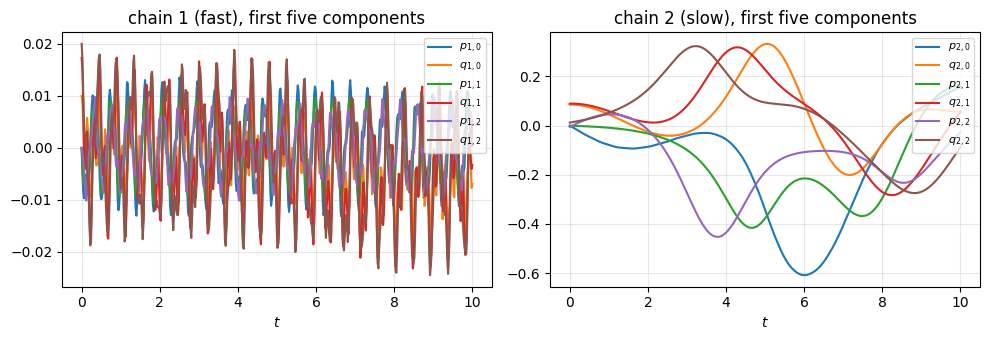

In [ ]:
t_ref = np.linspace(tspan[0], tspan[1], 500)
x_ref = sol.sol(t_ref)
label = lambda i, j: f"${'p' if j % 2 == 0 else 'q'}_{{{i},{j // 2}}}$"

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for j in range(6):
    axs[0].plot(t_ref, x_ref[j], label=label(1, j))
for j in range(6):
    axs[1].plot(t_ref, x_ref[2*N1 + 1 + j], label=label(2, j))
axs[0].set_title('chain 1 (fast), first six components')
axs[1].set_title('chain 2 (slow), first six components')
for ax in axs:
    ax.set_xlabel('$t$')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
matplot2tikz.save("MSD_reference.tex")
plt.show()

# Implementation of the Hierarchical Splitting Methods

All flows propagate the full state $x$.

The conservative subsystems are integrated by the modified discrete gradient method of order four, which is energy-consistent: the average vector field discrete gradient is evaluated exactly by the two-point Gauss-Legendre rule, since $\nabla \mathcal{H}$ is cubic, and the resulting nonlinear equation is solved by Newton's method with analytic Jacobian. The flow of the dissipative subsystem is computed exactly.

A fast flow over a time $\tau$ is performed by `n_substeps` micro steps, chosen as the smallest number for which the micro step size does not exceed $h/M$ with the multirate factor $M$.

In [7]:
GL2_NODES = (0.5 - np.sqrt(3.0) / 6.0, 0.5 + np.sqrt(3.0) / 6.0)

def J_flow(system, x, tau, key, tol=1e-12, maxiter=50):
    """
    Discrete gradient step of length tau for the subsystem y' = J grad H(y) with key 'fast' or 'slow':

        (y1 - y0)/tau = Jbar grad_AVF H(y0, y1),   Jbar = J - tau^2/12 J D J D J,   D = hess H((y0 + y1)/2)

    (modified discrete gradient method of order 4). The AVF integral is evaluated exactly by 2-point Gauss-Legendre
    quadrature (H is quartic). The implicit equation is solved by Newton's method with analytic Jacobian, initial guess y0,
    stopped if |dy|_max <= tol (1 + |y|_max).
    """
    a, b, J, eye, idx = system.dgm[key]
    s12 = tau * tau / 12.0
    th1, th2 = GL2_NODES
    y0 = x[idx].copy()

    def F(y):
        y1, y2 = y0 + th1 * (y - y0), y0 + th2 * (y - y0)
        g = 0.5 * (a * (y1 + y2) + b * (y1**3 + y2**3))       # grad_AVF H
        ym = 0.5 * (y0 + y)
        d = a + 3.0 * b * ym * ym                              # diag hess H(ym)
        v = J @ g
        return y - y0 - tau * (v - s12 * (J @ (d * (J @ (d * v)))))

    def jac(y):
        y1, y2 = y0 + th1 * (y - y0), y0 + th2 * (y - y0)
        g = 0.5 * (a * (y1 + y2) + b * (y1**3 + y2**3))
        G = 0.5 * (th1 * (a + 3.0 * b * y1 * y1) + th2 * (a + 3.0 * b * y2 * y2))  # dg/dy (diagonal)
        ym = 0.5 * (y0 + y)
        d = a + 3.0 * b * ym * ym
        dd = 3.0 * b * ym                                       # dd/dy (diagonal)
        al = J @ g
        ga = J @ (d * al)
        P = (J * d) @ J                                         # J D J
        Q = (P * d) @ J                                         # J D J D J
        # d/dy [Jbar(ym) g(y)] = Jbar G + (dJbar/dy) g, diagonal matrices as column scalings
        inner = (J - s12 * Q) * G - s12 * (J * (ga * dd) + P * (al * dd))
        return eye - tau * inner

    y = y0.copy()
    for _ in range(maxiter):
        try:
            dy = np.linalg.solve(jac(y), -F(y))
        except np.linalg.LinAlgError:
            raise RuntimeError(f"DGM4 ({key}): singular Jacobian") from None
        y += dy
        if not np.all(np.isfinite(y)):
            raise RuntimeError(f"DGM4 ({key}): Newton iterates not finite")
        if np.abs(dy).max() <= tol * (1.0 + np.abs(y).max()):
            break
    else:
        raise RuntimeError(f"DGM4 ({key}): Newton not converged after {maxiter} iterations")
    x[idx] = y
    return x


def J_slow_flow(system, x, tau):
    return J_flow(system, x, tau, 'slow')


def J_fast_flow(system, x, tau, nsub):
    """Multiple time stepping: fast flow over tau by nsub steps of length tau/nsub."""
    for _ in range(nsub):
        J_flow(system, x, tau / nsub, 'fast')
    return x


def n_substeps(tau, tau_max):
    """Smallest number n >= 1 of substeps with |tau|/n <= tau_max (-1e-9 guards against rounding)."""
    return max(1, int(np.ceil(abs(tau) / tau_max - 1e-9)))


def R_flow(system, x, tau):
    """Exact damping flow over tau."""
    x[system.R_idx] *= np.exp(tau * system.R_lam)
    return x

The composition scheme `BMs6p4` of Blanes and Moan serves as reference method. It is applied to a multirate Lie--Trotter method and its adjoint. Instead of calling the base scheme twelve times with step sizes $\alpha_i h$, we directly implement the composition to merge subsequent evaluations of the same flow, resulting in less flow evaluations while resulting in the same method.

Since the composition involves negative weights, the dissipative subsystem is integrated backward in time in some of the sub-steps. The method is therefore not energy-consistent.

In [ ]:
# Blanes & Moan (2002), six-stage method of order 4:  e^{a_1 A} e^{b_1 B} ... e^{b_6 B} e^{a_7 A}
BM_A = [0.0792036964311957, 0.353172906049774, -0.0420650803577195]
BM_A = BM_A + [1.0 - 2.0 * sum(BM_A)] + BM_A[::-1]
BM_B = [0.209515106613362, -0.143851773179818]
BM_B = BM_B + [0.5 - sum(BM_B)]
BM_B = BM_B + BM_B[::-1]
# equivalent composition  psi_h = chi_{al_12 h} o chi*_{al_11 h} o ... o chi_{al_2 h} o chi*_{al_1 h}  of a Lie-Trotter
# method chi and its adjoint chi*:  a_1 = al_1,  b_j = al_{2j-1} + al_{2j},  a_{j+1} = al_{2j} + al_{2j+1}
BM_ALPHA = [BM_A[0]]
for j in range(6):
    BM_ALPHA.append(BM_B[j] - BM_ALPHA[-1])
    if j < 5:
        BM_ALPHA.append(BM_A[j + 1] - BM_ALPHA[-1])


def BMs6p4(system, x0, tspan, nsteps, M):
    """
    Blanes & Moan s6p4 with chi_tau = R o J_fast o J_slow and chi*_tau = J_slow o J_fast o R. Each pair
    chi_{al_{2j} h} o chi*_{al_{2j-1} h} is executed as R, J_fast, J_slow (merged), J_fast, R.
    A fast flow over tau = al h uses n_substeps(tau, h/M) substeps.
    """
    h = (tspan[1] - tspan[0]) / nsteps
    nsub = [n_substeps(al * h, h / M) for al in BM_ALPHA]

    t = np.linspace(tspan[0], tspan[1], nsteps + 1)
    x = np.zeros((len(x0), nsteps + 1))
    x[:, 0] = x0
    y = np.array(x0, dtype=float)
    for n in range(nsteps):
        for j in range(6):
            t1, t2 = BM_ALPHA[2*j] * h, BM_ALPHA[2*j+1] * h
            R_flow(system, y, t1)
            J_fast_flow(system, y, t1, nsub[2*j])
            J_slow_flow(system, y, t1 + t2)
            J_fast_flow(system, y, t2, nsub[2*j+1])
            R_flow(system, y, t2)
        x[:, n+1] = y
    return t, x

Implementation of the `HSM4` method, the fourth-order energy-consistent hierarchical splitting method of Section 5.2. The root node carries the commutator-based splitting method

$$\Phi_h = \varphi^{\{3\}}_{h/6} \circ \tilde{\varphi}^{\{1,2\}}_{h/2} \circ \varphi^{\{3\}}_{2h/3} \circ \tilde{\varphi}^{\{1,2\}}_{h/2} \circ \varphi^{\{3\}}_{h/6},$$

where $\tilde{\varphi}^{\{1,2\}}$ denotes the flow of the force-gradient perturbed conservative subsystem, assembled in `fg_dgm`. The node $\{1,2\}$ carries the triple-jump composition of the Strang splitting with the fast subsystem on the outside, and the nodes $\{1\}$ and $\{2\}$ carry the modified discrete gradient method. To the dissipative node $\{3\}$, the corresponding exact flow is assigned.

All methods assigned to the nodes are convergent of order four (or exact), so that the overall method `HSM4` is of order four. Moreover, the negative weight of the triple-jump composition enters only the conservative subsystems, such that the dissipative subsystem is integrated only forward in time and the method is energy-consistent.

In [9]:
gamma1 = 1.0/(2.0-2.0**(1/3))
gamma2 = 1-2*gamma1


def fg_dgm(system, h):
    """
    Subsystem data for the force-gradient perturbation  J - h^2/72 [N,[N,J]],  N = diag(nu),  nu_j = -r_j a_j
    (constant, since b = 0 on the damped components): entrywise  J_ij (1 - h^2/72 (nu_i - nu_j)^2).
    """
    nu = -system.r * system.a
    W = 1.0 - h*h/72.0 * (nu[:, None] - nu[None, :])**2
    return {key: (a, b, J * W[np.ix_(idx, idx)], eye, idx) for key, (a, b, J, eye, idx) in system.dgm.items()}


def HSM4(system, x0, tspan, nsteps, M):
    """
    Fourth-order energy-consistent hierarchical splitting method

        R(h/6) o Jt(h/2) o R(2h/3) o Jt(h/2) o R(h/6),

    Jt(h/2): triple jump (gamma1, gamma2, gamma1) of Strang steps J_fast o J_slow o J_fast for the force-gradient
    perturbed structure matrix (fg_dgm). Each fast flow over tau uses n_substeps(tau, h/M) substeps.
    """
    h = (tspan[1] - tspan[0]) / nsteps
    sysJ = copy.copy(system)
    sysJ.dgm = fg_dgm(system, h)
    tau_a, tau_b = gamma1*h/4, (gamma1+gamma2)*h/4
    M_a, M_b = n_substeps(tau_a, h/M), n_substeps(tau_b, h/M)

    def Jt(y):
        J_fast_flow(sysJ, y, tau_a, M_a)
        J_slow_flow(sysJ, y, gamma1*h/2)
        J_fast_flow(sysJ, y, tau_b, M_b)
        J_slow_flow(sysJ, y, gamma2*h/2)
        J_fast_flow(sysJ, y, tau_b, M_b)
        J_slow_flow(sysJ, y, gamma1*h/2)
        J_fast_flow(sysJ, y, tau_a, M_a)

    t = np.linspace(tspan[0], tspan[1], nsteps + 1)
    x = np.zeros((len(x0), nsteps + 1))
    x[:, 0] = x0
    y = np.array(x0, dtype=float)
    for n in range(nsteps):
        R_flow(system, y, h/6)
        Jt(y)
        R_flow(system, y, 2*h/3)
        Jt(y)
        R_flow(system, y, h/6)
        x[:, n+1] = y
    return t, x

As a second reference method, we consider `DGM4`, the fourth-order modified discrete gradient method (Lautwein et al.) applied to the pH-ODE without any splitting and without multiple time stepping. The multirate factor is not used and is only kept for a uniform interface with the splitting methods.

In [10]:
def DGM4(system, x0, tspan, nsteps, M=None, tol=1e-12, maxiter=50):
    """
    Fourth-order discrete gradient method for the monolithic system  x' = (J - R) grad H(x)  (no splitting, no multiple time
    stepping; the multirate factor M is not used and only kept for a uniform interface with the splitting methods):

        (x1 - x0)/h = Abar(xm) grad_AVF H(x0, x1),    xm = (x0 + x1)/2,
        Abar(x) = A - h^2/12 A K A K A - h^4 C^T R C,    A = J - R,  K = hess H(x),  C = -1/12 (K J)^2 - 1/24 (K R)^2.

    K and R are diagonal, R is nonzero only on the index set q = R_idx. The AVF integral is evaluated exactly by 2-point
    Gauss-Legendre quadrature (H is quartic). The implicit equation is solved by Newton's method with analytic Jacobian, as in
    J_flow: initial guess x0, stopped if |dy|_max <= tol (1 + |y|_max).
    """
    h = (tspan[1] - tspan[0]) / nsteps
    a, b, r, J = system.a, system.b, system.r, system.J
    A = J - np.diag(r)
    eye = np.eye(system.n)
    q = system.R_idx
    rq, Jq, Jc, iq = r[q], J[q, :], J[:, q], np.arange(len(q))
    th1, th2 = GL2_NODES
    h2_12, h4 = h * h / 12.0, h**4

    def step(y0):
        def F(y):
            y1, y2 = y0 + th1 * (y - y0), y0 + th2 * (y - y0)
            g = 0.5 * (a * (y1 + y2) + b * (y1**3 + y2**3))       # grad_AVF H
            ym = 0.5 * (y0 + y)
            d = a + 3.0 * b * ym * ym                              # diag hess H(ym)
            s = r * (-(d * (J @ (d * (J @ g)))) / 12.0 - (d * r)**2 * g / 24.0)           # R C g
            v = A @ g - h2_12 * (A @ (d * (A @ (d * (A @ g))))) \
                - h4 * (-(J @ (d * (J @ (d * s)))) / 12.0 - (d * r)**2 * s / 24.0)        # Abar g
            return y - y0 - h * v

        def jac(y):
            y1, y2 = y0 + th1 * (y - y0), y0 + th2 * (y - y0)
            g = 0.5 * (a * (y1 + y2) + b * (y1**3 + y2**3))
            G = 0.5 * (th1 * (a + 3.0 * b * y1 * y1) + th2 * (a + 3.0 * b * y2 * y2))  # dg/dy (diagonal)
            ym = 0.5 * (y0 + y)
            d = a + 3.0 * b * ym * ym
            dd = 3.0 * b * ym                                       # dd/dy (diagonal)
            dq, rr = d[q], r * r * d
            AKA = (A * d) @ A                                       # A K A
            Sq = (Jq * d) @ J                                       # rows q of J K J (symmetric)
            Cq = Sq * (-dq[:, None] / 12.0)                         # rows q of C
            Cq[iq, q] -= (dq * rq)**2 / 24.0
            CTR = Cq.T * rq                                         # C^T R
            # d/dy [Abar(ym) g(y)] = Abar G + (dAbar/dd g) dd, diagonal matrices as column scalings
            w2 = A @ g
            w1 = A @ (d * w2)
            sq = rq * (Cq @ g)                                      # (R C g)_q
            Psi = (Jq * (-dq[:, None] / 12.0)) * (J @ g)            # rows q of (dC/dd_j) g
            Psi[iq, q] -= (Sq @ g + rr[q] * g[q]) / 12.0
            Phi = J * (-(Jc @ (dq * sq)) * dd / 12.0)               # (dC/dd_j)^T R C g
            Phi[:, q] -= Sq.T * (sq * dd[q] / 12.0)
            Phi[q, q] -= rr[q] * sq * dd[q] / 12.0
            Z = Cq * G + Psi * dd
            Mat = A * (G - h2_12 * w1 * dd) - h2_12 * (AKA * (w2 * dd) + ((AKA * d) @ A) * G) - h4 * (Phi + CTR @ Z)
            return eye - h * Mat

        y = y0.copy()
        for _ in range(maxiter):
            try:
                dy = np.linalg.solve(jac(y), -F(y))
            except np.linalg.LinAlgError:
                raise RuntimeError("DGM4: singular Jacobian") from None
            y += dy
            if not np.all(np.isfinite(y)):
                raise RuntimeError("DGM4: Newton iterates not finite")
            if np.abs(dy).max() <= tol * (1.0 + np.abs(y).max()):
                return y
        raise RuntimeError(f"DGM4: Newton not converged after {maxiter} iterations")

    t = np.linspace(tspan[0], tspan[1], nsteps + 1)
    x = np.zeros((len(x0), nsteps + 1))
    x[:, 0] = x0
    y = np.array(x0, dtype=float)
    for n in range(nsteps):
        y = step(y)
        x[:, n+1] = y
    return t, x

# Numerical tests

## Work-precision diagram

The accuracy is measured by the discrete $L^2$ error with respect to the reference solution of the weakly damped configuration. The multirate factors have been tuned for each method. A method is no longer run for smaller step sizes once one of its runs has exceeded the CPU time budget.

BMs6p4               M =  32, nsteps =    16, h = 6.250e-01:  CPU =    0.287 s,  L2 error = 2.115e-02
HSM                  M =  30, nsteps =    16, h = 6.250e-01:  CPU =    0.210 s,  L2 error = 4.312e-02
DGM4                 M =   1, nsteps =    16, h = 6.250e-01:  CPU =    0.023 s,  L2 error = 2.976e-01
BMs6p4               M =  32, nsteps =    24, h = 4.167e-01:  CPU =    0.362 s,  L2 error = 8.278e-03
HSM                  M =  30, nsteps =    24, h = 4.167e-01:  CPU =    0.275 s,  L2 error = 1.557e-02
DGM4                 M =   1, nsteps =    24, h = 4.167e-01:  CPU =    0.032 s,  L2 error = 2.474e-01
BMs6p4               M =  32, nsteps =    32, h = 3.125e-01:  CPU =    0.470 s,  L2 error = 3.643e-03
HSM                  M =  30, nsteps =    32, h = 3.125e-01:  CPU =    0.356 s,  L2 error = 6.868e-03
DGM4                 M =   1, nsteps =    32, h = 3.125e-01:  CPU =    0.042 s,  L2 error = 2.396e-01
BMs6p4               M =  32, nsteps =    48, h = 2.083e-01:  CPU =    0.694 s,  L

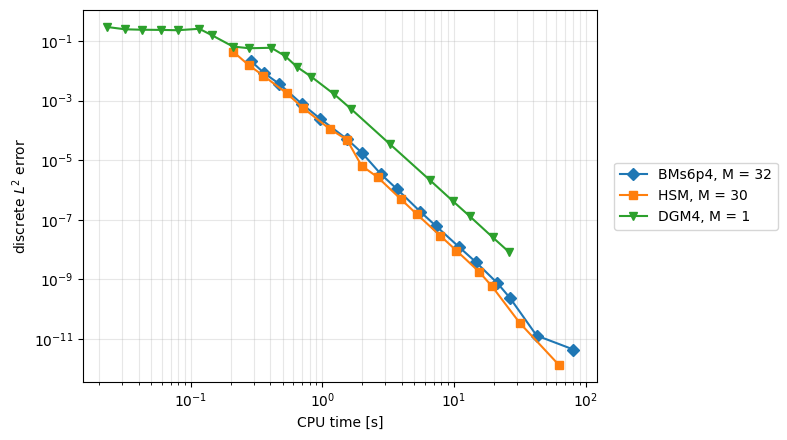

In [11]:
nsteps_list = [16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048, 4096, 8192, 12288, 16384, 24576, 32768]
T = tspan[1] - tspan[0]

# multirate factors M (tuned for each method)
methods = {'BMs6p4': (BMs6p4, 32),
           'HSM4': (HSM4, 30),
           'DGM4': (DGM4, 1)}      # monolithic discrete gradient method, M is not used

CPU_MAX = 60.0      # [s] a method is not run for larger nsteps once one of its runs has needed more than CPU_MAX
active = set(methods)
wp = {name: {'h': [], 'cpu': [], 'err': []} for name in methods}
for nsteps in nsteps_list:
    h = T / nsteps
    for name, (method, M) in methods.items():
        if name not in active:
            continue
        c0 = time.process_time()
        t_num, x_num = method(system_wp, x0, tspan, nsteps, M)
        cpu = time.process_time() - c0
        err = np.sqrt(h * np.sum((x_num - sol.sol(t_num))**2))     # discrete L2 error w.r.t. the reference solution
        wp[name]['h'].append(h)
        wp[name]['cpu'].append(cpu)
        wp[name]['err'].append(err)
        print(f"{name:20s} M = {M:3d}, nsteps = {nsteps:5d}, h = {h:.3e}:  CPU = {cpu:8.3f} s,  L2 error = {err:.3e}")
        if cpu > CPU_MAX:
            active.discard(name)
            print(f"{name:20s} CPU time exceeds {CPU_MAX:.0f} s: not run for larger nsteps")

fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, (method, M)), marker in zip(methods.items(), ['D', 's', 'v']):
    ax.loglog(wp[name]['cpu'], wp[name]['err'], marker=marker, label=f"{name}, M = {M}")
ax.set_xlabel('CPU time [s]')
ax.set_ylabel(r'discrete $L^2$ error')
ax.grid(True, which='both', alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
matplot2tikz.save("MSD_workprecision.tex")
plt.show()

## Convergence

The same data, plotted against the step size, together with the empirical orders. All three methods are expected to attain order four; `DGM4` reaches it only for smaller step sizes, since its global step size has to resolve the fast chain.

BMs6p4               (M = 32) empirical orders:  2.31   2.85   3.77   4.02   3.95   3.69   4.05   4.01   4.23   3.97   3.99   4.00   4.00   4.02   4.17   1.56
HSM                  (M = 30) empirical orders:  2.51   2.85   3.34   3.86   4.06   2.90   4.96   3.06   4.17   4.12   4.04   4.02   4.01   4.01   4.07   4.71
DGM4                 (M =  1) empirical orders:  0.46   0.11   0.04   0.09  -0.27   1.74   2.15   0.46  -0.09   2.17   2.13   2.57   3.38   3.89   3.97   3.99   4.00   4.00   4.00   4.00


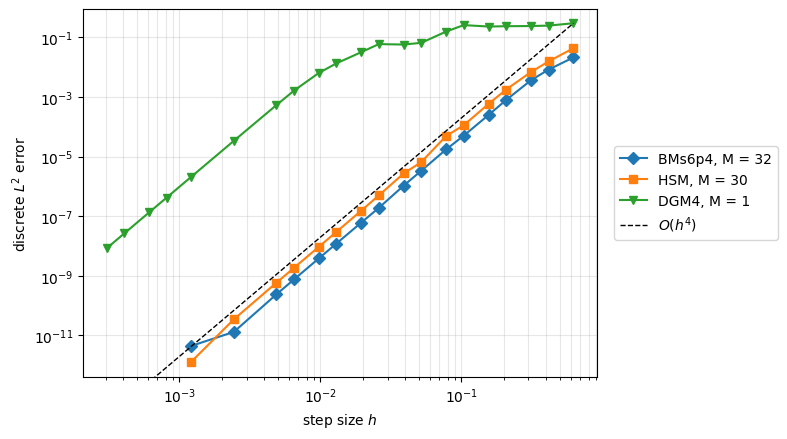

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, (method, M)), marker in zip(methods.items(), ['D', 's', 'v']):
    hs, errs = np.array(wp[name]['h']), np.array(wp[name]['err'])
    ax.loglog(hs, errs, marker=marker, label=f"{name}, M = {M}")
    p = np.log(errs[:-1] / errs[1:]) / np.log(hs[:-1] / hs[1:])
    print(f"{name:20s} (M = {M:2d}) empirical orders: " + "  ".join(f"{pk:5.2f}" for pk in p))

# reference lines of order 2 and 4
h_all = np.array(sorted({hk for d in wp.values() for hk in d['h']}))
e_min = min(min(d['err']) for d in wp.values())
e_max = max(max(d['err']) for d in wp.values())
ax.loglog(h_all, e_max * (h_all / h_all[-1])**4, 'k--', lw=1, label=f'$O(h^{4})$')
ax.set_ylim(0.3 * e_min, 3 * e_max)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('step size $h$')
ax.set_ylabel(r'discrete $L^2$ error')
ax.grid(True, which='both', alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
matplot2tikz.save("MSD_order.tex")
plt.show()

## Investigations of the energy behavior

Finally, we consider the stiffly damped configuration, for which the Hamiltonian is non-increasing along the exact solution. A numerical solution should therefore satisfy $\max_n \left[ \mathcal{H}(x_{n+1}) - \mathcal{H}(x_n) \right]/h \leq 0$. The column "exact" reports the same quantity for the reference solution on the same time grid. This configuration offers no multirate potential to exploit, so that we set $M = 1$ for all methods.

In [13]:
stab_methods = {'BMs6p4': BMs6p4,
                'HSM4': HSM4,
                'DGM4': DGM4}
nsteps_stab = [2**k for k in range(2, 15)]
M_stab = 1
CPU_MAX = 60.0      # [s] a method is skipped for larger nsteps once one of its runs has needed more than CPU_MAX
skipped = set()

sol_stab = solve_ivp(system_stab.f, tspan, x0, method='Radau', rtol=1e-11, atol=1e-13, dense_output=True)

header = "| $h$ | exact | " + " | ".join(f"{name} (M = {M_stab})" for name in stab_methods) + " |"
rule = "|---:|---:|" + "---:|" * len(stab_methods)
table = [header, rule]
for nsteps in nsteps_stab:
    h = (tspan[1] - tspan[0]) / nsteps
    H_ex = np.array([system_stab.H(sol_stab.sol(tn)) for tn in np.linspace(tspan[0], tspan[1], nsteps + 1)])
    cells_dH = [f"{np.max(np.diff(H_ex)) / h:+.2e}"]
    for name, method in stab_methods.items():
        if name in skipped:
            cells_dH.append("skipped")
            continue
        c0 = time.process_time()
        try:
            with np.errstate(over='ignore', invalid='ignore'):
                t_num, x_num = method(system_stab, x0, tspan, nsteps, M_stab)
                H = np.array([system_stab.H(x_num[:, n]) for n in range(nsteps + 1)])
                dH = np.max(np.diff(H)) / h
            cells_dH.append(f"{dH:+.2e}" if np.isfinite(dH) else "diverged")
        except RuntimeError:
            cells_dH.append("solver failed")
        if time.process_time() - c0 > CPU_MAX:
            skipped.add(name)
    table.append(f"| {h:.3e} | " + " | ".join(cells_dH) + " |")

display(Markdown("**Largest discrete energy change rate** $\\max_n\\,(H(x_{n+1}) - H(x_n))/h$\n\n" + "\n".join(table)))

**Largest discrete energy change rate** $\max_n\,(H(x_{n+1}) - H(x_n))/h$

| $h$ | exact | BMs6p4 (M = 1) | HSM (M = 1) | DGM4 (M = 1) |
|---:|---:|---:|---:|---:|
| 2.500e+00 | -1.37e-03 | solver failed | +4.44e-17 | -4.68e-07 |
| 1.250e+00 | -1.17e-03 | solver failed | +0.00e+00 | -7.60e-07 |
| 6.250e-01 | -1.06e-03 | solver failed | +1.78e-16 | -1.25e-05 |
| 3.125e-01 | -1.01e-03 | solver failed | +5.33e-16 | -2.43e-04 |
| 1.562e-01 | -9.80e-04 | solver failed | -1.84e-12 | -1.69e-04 |
| 7.812e-02 | -9.67e-04 | solver failed | -2.01e-06 | -3.83e-06 |
| 3.906e-02 | -9.61e-04 | solver failed | -7.62e-05 | -3.37e-11 |
| 1.953e-02 | -9.57e-04 | solver failed | -8.24e-06 | -2.38e-10 |
| 9.766e-03 | -9.56e-04 | +1.34e+02 | -6.64e-10 | -9.29e-09 |
| 4.883e-03 | -9.55e-04 | -1.03e-03 | -7.68e-04 | -1.50e-07 |
| 2.441e-03 | -9.55e-04 | -9.60e-04 | -1.09e-03 | -1.19e-04 |
| 1.221e-03 | -9.54e-04 | -9.55e-04 | -9.71e-04 | -9.85e-04 |
| 6.104e-04 | -9.54e-04 | -9.54e-04 | -9.55e-04 | -9.56e-04 |